# São Miguel --> Ilha 27

In [69]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
import pickle 
from tqdm import tqdm
import numpy as np
from sklearn.metrics import mean_squared_error

df_27 = pd.read_csv('df_27_d.csv')
df_27_y = pd.read_csv('df_27_y_d.csv')

df_27['ID'] = [i for i in range(len(df_27))]
df_27_y['ID'] = [i for i in range(len(df_27_y))]

# Coluna = 'Unnamed: 0' --> corresponde aos id reais!! <-- IMP

In [70]:
df_27

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,3,2015,0.357143,Swimming pool,0.20,0.20,True,0.285714,0.672806,-0.238325,0
1,5,1995,0.357143,Air conditioning,0.68,0.36,True,0.142857,0.672898,-0.238849,1
2,29,1937,0.214286,True,0.12,0.12,True,0.428571,0.672457,-0.238641,2
3,31,2006,0.285714,True,0.26,0.24,True,0.142857,0.672402,-0.239117,3
4,36,1937,0.214286,True,0.14,0.14,True,1.000000,0.672806,-0.238325,4
...,...,...,...,...,...,...,...,...,...,...,...
988,4464,True,0.142857,True,0.14,0.14,c,0.142857,0.672353,-0.238931,988
989,4475,True,0.285714,True,0.16,0.16,True,0.428571,0.673960,-0.235996,989
990,4476,1992,0.285714,Garden,0.12,0.12,True,0.428571,0.672712,-0.238785,990
991,4480,True,0.285714,Air conditioning,0.36,0.36,True,0.142857,0.673930,-0.239091,991


# Pre-processamento 

### Colunas: 
- built_in
- amenities
- energetic_efficiency

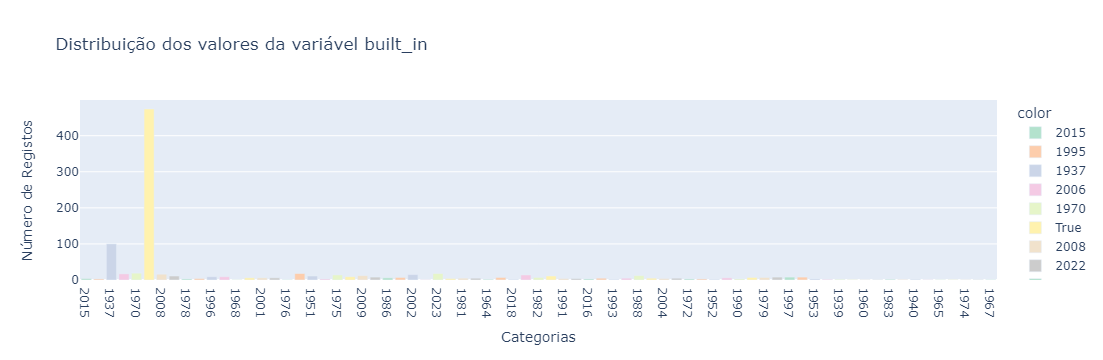

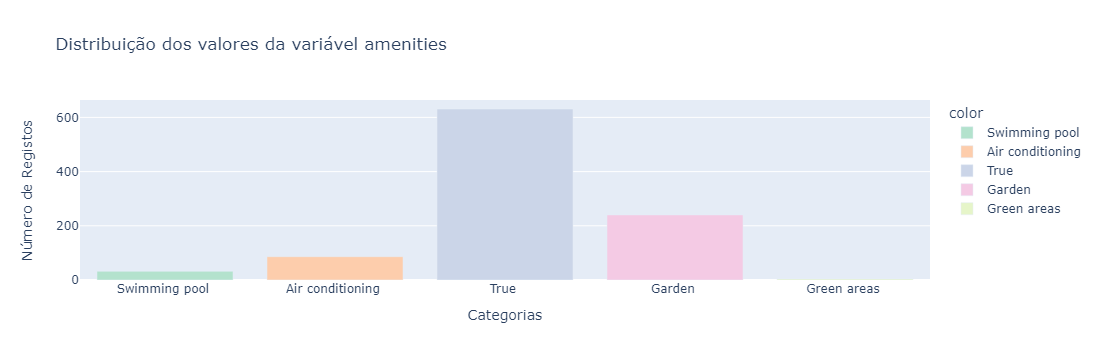

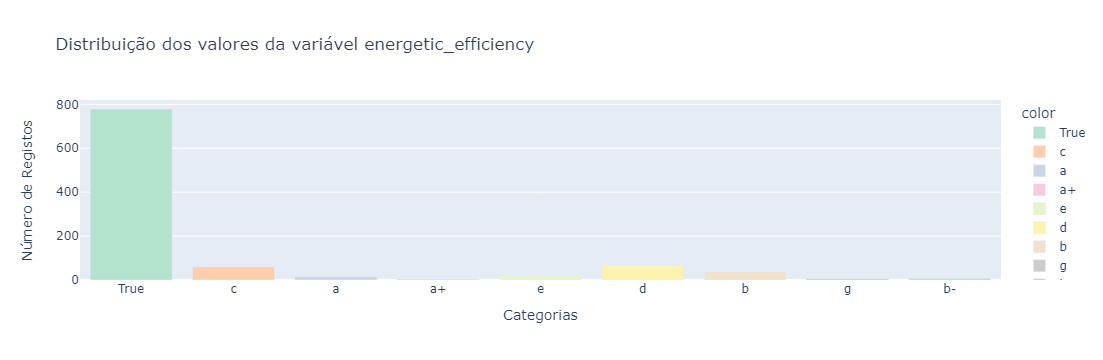

In [71]:
# Variação dos dados 
import plotly.express as px
col = ['built_in', 'amenities','energetic_efficiency']

for nome in col: 
    output = []
    names = df_27[nome].unique()
    for i in df_27[nome].unique():
        bt2 = df_27[nome].value_counts()[i]
        output.append(bt2)
    fig = px.bar(df_27, x=names, y=output, color = names ,color_discrete_sequence= px.colors.qualitative.Pastel2, title= f'Distribuição dos valores da variável {nome}')
    fig.update_xaxes(title_text='Categorias')
    fig.update_yaxes(title_text='Número de Registos')
    fig.show()

### --> Eficiência Energética

In [72]:
from sklearn.neighbors import KNeighborsClassifier
# Cluster para ver as casas mais parecidas, para depois asoociar um valor aos imóveis que não têm eficiencia energética

# Obter ID onde energetic_efficiency == 'True' e ou != 'True'
ids_true27 = list(df_27.loc[df_27['energetic_efficiency'] == 'True', 'ID']) # O que vão ser previstos 
ids_outros27 = list(df_27.loc[df_27['energetic_efficiency'] != 'True', 'ID'])


# Dados 
teste27 = df_27.loc[ids_true27,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
#teste_y27 = df_27.loc[ids_true27,['energetic_efficiency']]
treino27 = df_27.loc[ids_outros27,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
treino_y27 = df_27.loc[ids_outros27,['energetic_efficiency']]

# Comparação --> X_train_27[['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
def KNN(k, teste, treino, treino_y):
    knn =  KNeighborsClassifier(n_neighbors=k)
    knn.fit(treino, treino_y)
    y_pred = knn.predict(teste)
    return y_pred
l_ee27 = KNN(3, teste27, treino27, treino_y27)

# Substituir os True

def sub_ee(ids_true, l_ee, df, col):
    for i in range(len(ids_true)): 
        df.loc[df['ID'] == ids_true[i], col] = l_ee[i]
    return df
df_27 = sub_ee(ids_true27, l_ee27, df_27, 'energetic_efficiency')


ee27 = df_27.loc[:, ['energetic_efficiency']]

def substituir_energetic_efficiency(X):
    X = X.replace('a+', 1)
    X = X.replace('a', 2)
    X = X.replace('b', 3)
    X = X.replace('b-', 4)
    X = X.replace('c', 5)
    X = X.replace('d', 6)
    X = X.replace('e', 7)
    X = X.replace('f', 8)
    X = X.replace('g', 9)
    
    return X
ee27 = substituir_energetic_efficiency(ee27)

# normalizar valores 
def norm_ee(df1): 
    
    df1['energetic_efficiency'] = df1['energetic_efficiency'] /df1['energetic_efficiency'].abs().max()
    return df1
ee27 = norm_ee(ee27)

df_27['energetic_efficiency'] = ee27

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



### --> Amenities

In [73]:
aa27 = df_27.loc[:, ['amenities']]

def substituir_amenities(X):
    X = X.replace('True ', 1)
    X = X.replace('Air conditioning ', 2)
    X = X.replace('Garden ', 3)
    X = X.replace('Green areas ', 3)
    X = X.replace('Swimming pool ', 4)
    
    return X
aa27 = substituir_amenities(aa27)

# normalizar valores 
def norm_amenities(df1): 
    
    df1['amenities'] = df1['amenities'] /11
    return df1
aa27 = norm_amenities(aa27)

df_27['amenities'] = aa27

### --> built_in

In [74]:
id_true27 = list(df_27.loc[df_27['built_in'] == 'True', 'ID'])
id_outros27 = list(df_27.loc[df_27['built_in'] != 'True', 'ID'])

# Obter anos que têm menos de 2 samples 

def menos_2(df, nome): 
    l = []
    for i in df[nome].unique():
        bt2 = df[nome].value_counts()[i]
        if bt2 < 3: 
            l.append(i) 
    return l
lista_data27 = menos_2(df_27, 'built_in')

def replicação_menos2(df, lista_data, id_outros):
    for ano in lista_data: 
        id_ano = list(df.loc[df['built_in'] == ano, 'ID'])
        for i in range(len(id_ano)):
            id_outros.append(id_ano[i])
            id_outros.append(id_ano[i])
    return id_outros

id_outros27 = replicação_menos2(df_27, lista_data27, id_outros27)

# Dados 
# criar dataset com price

d_b27 =  df_27.loc[:,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
d_b_227 = df_27_y.loc[:,['Price_norm']]
#d_b = pd.concat([d_b_1, d_b_2])
d_b27 = d_b27.join(d_b_227)


teste_b27 = d_b27.loc[id_true27,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
#teste_y27 = df_27.loc[ids_true27,['built_in']]
treino_b27 = d_b27.loc[id_outros27,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
treino_b_y27 = df_27.loc[id_outros27,['built_in']]

# KNN
l_b_i27 = KNN(3, teste_b27, treino_b27, treino_b_y27)

# Substituir
df_27 = sub_ee(id_true27, l_b_i27, df_27, 'built_in')

b_i27 = df_27.loc[:, ['built_in']]
b_i27['built_in'] = b_i27['built_in'].astype(int)

# normalizar valores 
def norm_b_i(df1): 
    
    df1['built_in'] = df1['built_in'] /2024
    return df1
b_i27 = norm_b_i(b_i27)

df_27['built_in'] = b_i27

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



In [75]:
df_27

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,3,0.995553,0.357143,0.363636,0.20,0.20,0.333333,0.285714,0.672806,-0.238325,0
1,5,0.985672,0.357143,0.181818,0.68,0.36,0.222222,0.142857,0.672898,-0.238849,1
2,29,0.957016,0.214286,0.090909,0.12,0.12,0.555556,0.428571,0.672457,-0.238641,2
3,31,0.991107,0.285714,0.090909,0.26,0.24,0.111111,0.142857,0.672402,-0.239117,3
4,36,0.957016,0.214286,0.090909,0.14,0.14,0.555556,1.000000,0.672806,-0.238325,4
...,...,...,...,...,...,...,...,...,...,...,...
988,4464,0.957016,0.142857,0.090909,0.14,0.14,0.555556,0.142857,0.672353,-0.238931,988
989,4475,0.953557,0.285714,0.090909,0.16,0.16,0.333333,0.428571,0.673960,-0.235996,989
990,4476,0.984190,0.285714,0.272727,0.12,0.12,0.777778,0.428571,0.672712,-0.238785,990
991,4480,0.975791,0.285714,0.181818,0.36,0.36,0.333333,0.142857,0.673930,-0.239091,991


# Modelo

In [61]:

# Dividir em treino e teste

X_train_27, X_test_27, y_train_27, y_test_27 = train_test_split(df_27, df_27_y, test_size=0.30, random_state=42)
X_train_27

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
852,3829,0.999506,0.214286,0.090909,0.16,0.16,0.555556,1.000000,0.672726,-0.239234,852
751,3363,0.992589,0.428571,0.272727,0.50,0.48,0.666667,0.142857,0.673570,-0.238132,751
327,1494,0.991107,0.357143,0.090909,0.26,0.26,0.222222,0.142857,0.672846,-0.238383,327
792,3566,0.980731,0.357143,0.090909,0.42,0.12,0.333333,1.000000,0.674339,-0.235727,792
927,4162,0.986166,0.285714,0.090909,0.40,0.40,0.222222,0.142857,0.672624,-0.239413,927
...,...,...,...,...,...,...,...,...,...,...,...
106,541,0.976779,0.285714,0.272727,0.56,0.52,0.222222,0.142857,0.672758,-0.237967,106
270,1198,0.989130,0.785714,0.090909,0.74,0.70,0.555556,0.428571,0.672676,-0.238332,270
860,3865,0.992095,0.214286,0.090909,0.08,0.08,0.555556,0.285714,0.672806,-0.238325,860
435,1927,0.957016,0.214286,0.090909,0.58,0.58,0.666667,0.571429,0.672743,-0.237997,435


In [76]:
X_train27 = X_train_27[['tipology', 'amenities', 'built_in','energetic_efficiency', 'house_type']]
X_test27 = X_test_27[[ 'tipology', 'amenities', 'built_in', 'energetic_efficiency', 'house_type']]
y_train27 = y_train_27[['Price_norm']]
y_test27 = y_test_27[['Price_norm']]

# MLPRegressor

In [82]:
# Melhores parametros 

"""
regr = MLPRegressor(hidden_layer_sizes=(250,), activation='tanh',  solver='lbfgs',alpha=0.005, learning_rate= 'constant', learning_rate_init = 0.001,  tol = 0.0001, max_iter=1000).fit(X_train27, y_train27)
y_pred = regr.predict(X_test27)
y_pred = [abs(x) for x in y_pred]
#print(y_pred)
print(mean_squared_error(y_pred,y_test27))
print(regr.score(X_test27, y_test27))

### Guardar o modelo

import pickle

with open('modelo_dist27.pkl', 'wb') as file:
    pickle.dump(regr, file)
"""

0.00041686224746405965
0.24221771123185643


C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1625: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



In [83]:
# abrir modelo

with open('modelo_dist27.pkl', 'rb') as f:
    MLR = pickle.load(f)
MLR

MLPRegressor(activation='tanh', alpha=0.005, hidden_layer_sizes=(250,),
             max_iter=1000, solver='lbfgs')

In [84]:
y_prev = MLR.predict(X_test27)

# OUTPUT E VIS

In [85]:
y_test27['prev_norm'] = y_prev

C:\Users\User\AppData\Local\Temp\ipykernel_14236\4018819711.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [86]:
# Desnormalizar valores e Criar 'Price_prev'
def desnormalizar(valor):
    maximoout= 15000000 # depois mudar este valor, para o verdadeiro máximo
    return np.round(valor * maximoout,0)

def lista_des(lista): 
    n_l = []
    for i in lista: 
        n_l.append(desnormalizar(i))
    return n_l

y_test27['Price_prev'] = lista_des(y_prev)

def df_criar_id(y_test, df_13_y):
    y_test['Price_Real'] =[0] * len(y_test)
    for i in y_test.index:
        y_test['Price_Real'][i] = df_13_y['Price_Real'].iloc[i]
    return y_test
y_test27 = df_criar_id(y_test27, df_27_y)

C:\Users\User\AppData\Local\Temp\ipykernel_14236\2310009841.py:12: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_14236\2310009841.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_14236\2310009841.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_

In [87]:
# Crirar intervalo de preço

def intervalo_preco(y):
    l =  []
    for i in y['Price_prev']: 
        p_int = [i-(i*0.03), i+(i*0.03)]
        l.append(p_int)
    y['Price_Prev_Int'] = l
    return y

y_test27 =  intervalo_preco(y_test27)

In [88]:
y_test27

,Price_norm,prev_norm,Price_prev,Price_Real,Price_Prev_Int
918,0.003797,0.034278,514176.0,56950,"[498750.72, 529601.28]"
525,0.010667,0.024534,368016.0,160000,"[356975.52, 379056.48]"
567,0.014997,0.050335,755022.0,224950,"[732371.34, 777672.66]"
656,0.026000,0.023629,354431.0,390000,"[343798.07, 365063.93]"
915,0.008667,0.019991,299867.0,130000,"[290870.99, 308863.01]"
...,...,...,...,...,...
155,0.022667,0.024080,361204.0,340000,"[350367.88, 372040.12]"
538,0.011667,0.023823,357342.0,175000,"[346621.74, 368062.26]"
521,0.029933,0.030413,456198.0,449000,"[442512.06, 469883.94]"
522,0.006109,0.029757,446349.0,91630,"[432958.53, 459739.47]"


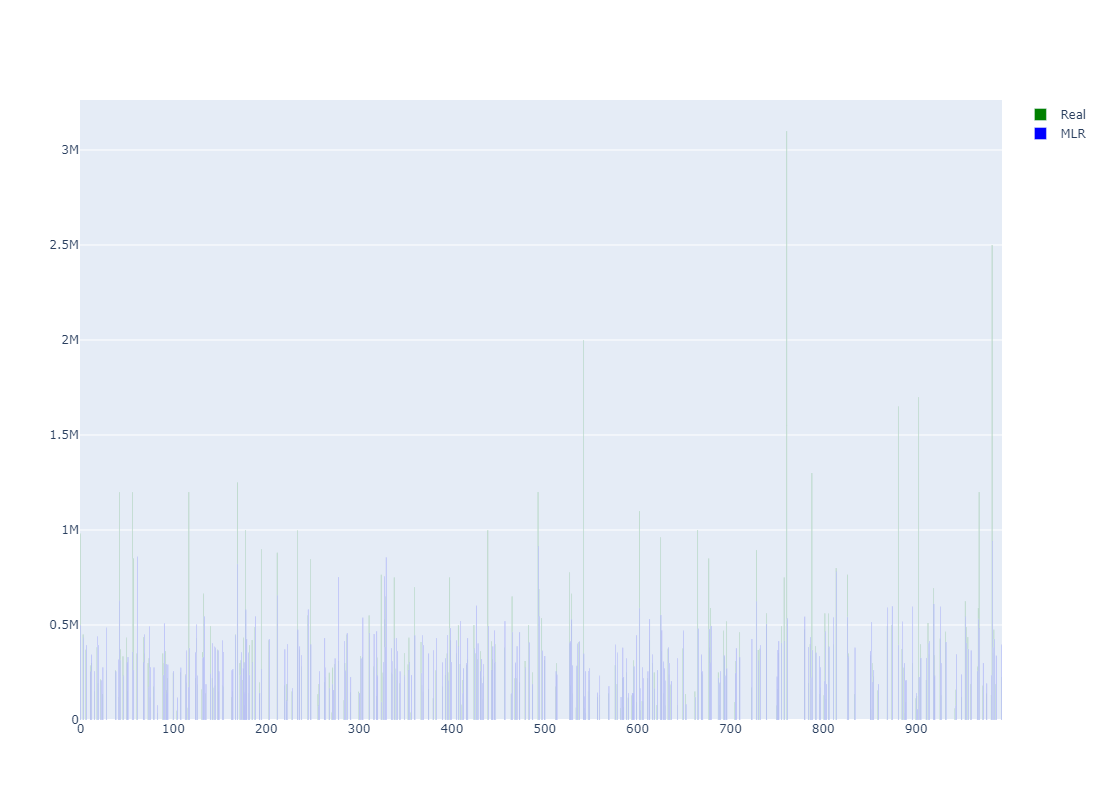

In [89]:
import plotly.graph_objects as go

# Grafico preço real e valor previsto
fig = go.Figure(
    data=[
        go.Bar(x=X_train_27.ID, y=y_test27.Price_Real, name="Real", marker_color='green'),
        go.Bar(x=X_train_27.ID, y=y_test27.Price_prev, name="MLR",  marker_color='blue'),
    ],
)
fig.update_layout(
    autosize=False,
    width=1000,
    height=800)

fig.show()